# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Muhammad Farid Wijdan | 5054251042 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch: {torch.__version__}")
print(f"Device yang digunakan: {device}")
print(f"Num threads CPU: {torch.get_num_threads()}")

torch: 2.15.0
Device yang digunakan: cpu
Num threads CPU: 4


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28x28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

df_train_raw = pd.read_csv("fashion-mnist_train.csv")
df_test_raw = pd.read_csv("fashion-mnist_test.csv")

print(f"Bentuk train: {df_train_raw.shape} (baris, kolom: 1 label + 784 piksel)")
print(f"Bentuk test : {df_test_raw.shape}")
print(f"Kolom pertama train: {list(df_train_raw.columns[:5])} ... (label + pixel0..pixel783)")
print(f"Rentang nilai piksel train: {df_train_raw.iloc[:, 1:].values.min()} - {df_train_raw.iloc[:, 1:].values.max()}")
print()
print("Contoh label 10 pertama (train):", df_train_raw.iloc[:10, 0].tolist())
print("Contoh label 10 pertama (test) :", df_test_raw.iloc[:10, 0].tolist())
print()
print("Ukuran ini sesuai deskripsi: 60.000 gambar train + 10.000 gambar test, total 70.000 gambar 28x28.")

Bentuk train: (60000, 785) (baris, kolom: 1 label + 784 piksel)
Bentuk test : (10000, 785)
Kolom pertama train: ['label', '0', '1', '2', '3'] ... (label + pixel0..pixel783)


Rentang nilai piksel train: 0 - 255

Contoh label 10 pertama (train): [9, 0, 0, 3, 0, 2, 7, 2, 5, 5]
Contoh label 10 pertama (test) : [9, 2, 1, 1, 6, 1, 4, 6, 5, 7]

Ukuran ini sesuai deskripsi: 60.000 gambar train + 10.000 gambar test, total 70.000 gambar 28x28.


Jumlah train per kelas:
label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000

Jumlah test per kelas:
label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000


/var/folders/1w/yqznhsk91cggg4l67976h2tw0000gn/T/ipykernel_97181/983563019.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels([class_names[i] for i in train_counts.index], rotation=45, ha="right")
/var/folders/1w/yqznhsk91cggg4l67976h2tw0000gn/T/ipykernel_97181/983563019.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels([class_names[i] for i in test_counts.index], rotation=45, ha="right")


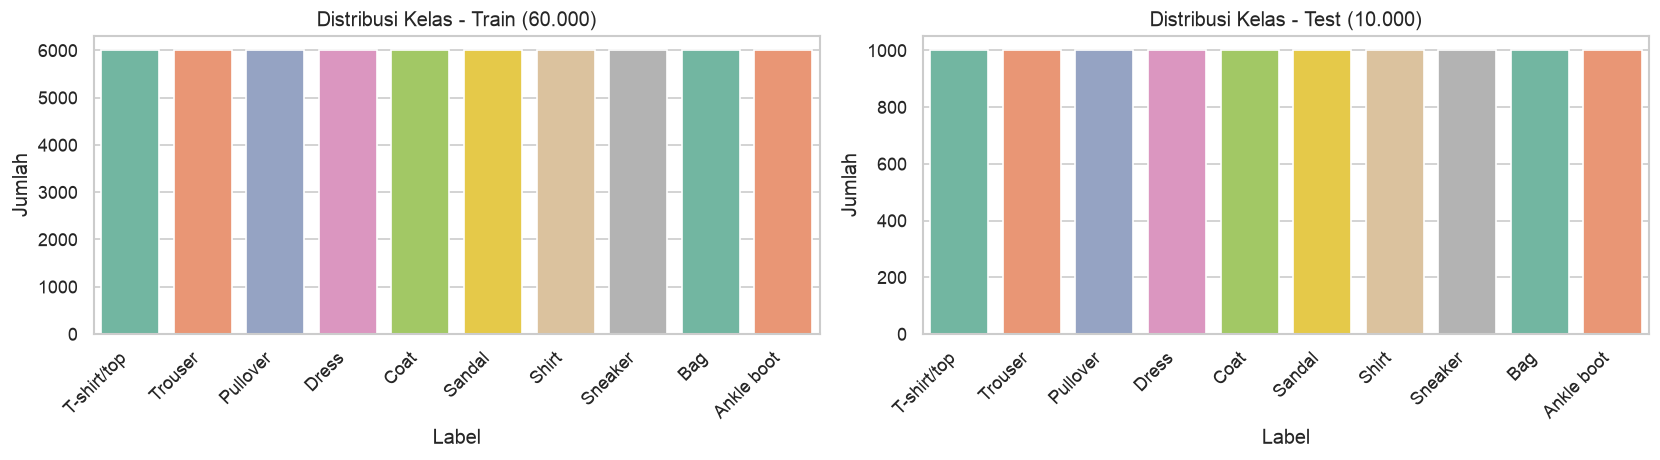

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = {
    0: "T-shirt/top", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle boot"
}
class_list = [class_names[i] for i in range(10)]

train_counts = df_train_raw.iloc[:, 0].value_counts().sort_index()
test_counts = df_test_raw.iloc[:, 0].value_counts().sort_index()
print("Jumlah train per kelas:")
print(train_counts.to_string())
print()
print("Jumlah test per kelas:")
print(test_counts.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=train_counts.index, y=train_counts.values, hue=train_counts.index, palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Distribusi Kelas - Train (60.000)")
axes[0].set_xlabel("Label"); axes[0].set_ylabel("Jumlah")
axes[0].set_xticklabels([class_names[i] for i in train_counts.index], rotation=45, ha="right")
sns.barplot(x=test_counts.index, y=test_counts.values, hue=test_counts.index, palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Distribusi Kelas - Test (10.000)")
axes[1].set_xlabel("Label"); axes[1].set_ylabel("Jumlah")
axes[1].set_xticklabels([class_names[i] for i in test_counts.index], rotation=45, ha="right")
plt.tight_layout()
plt.show()

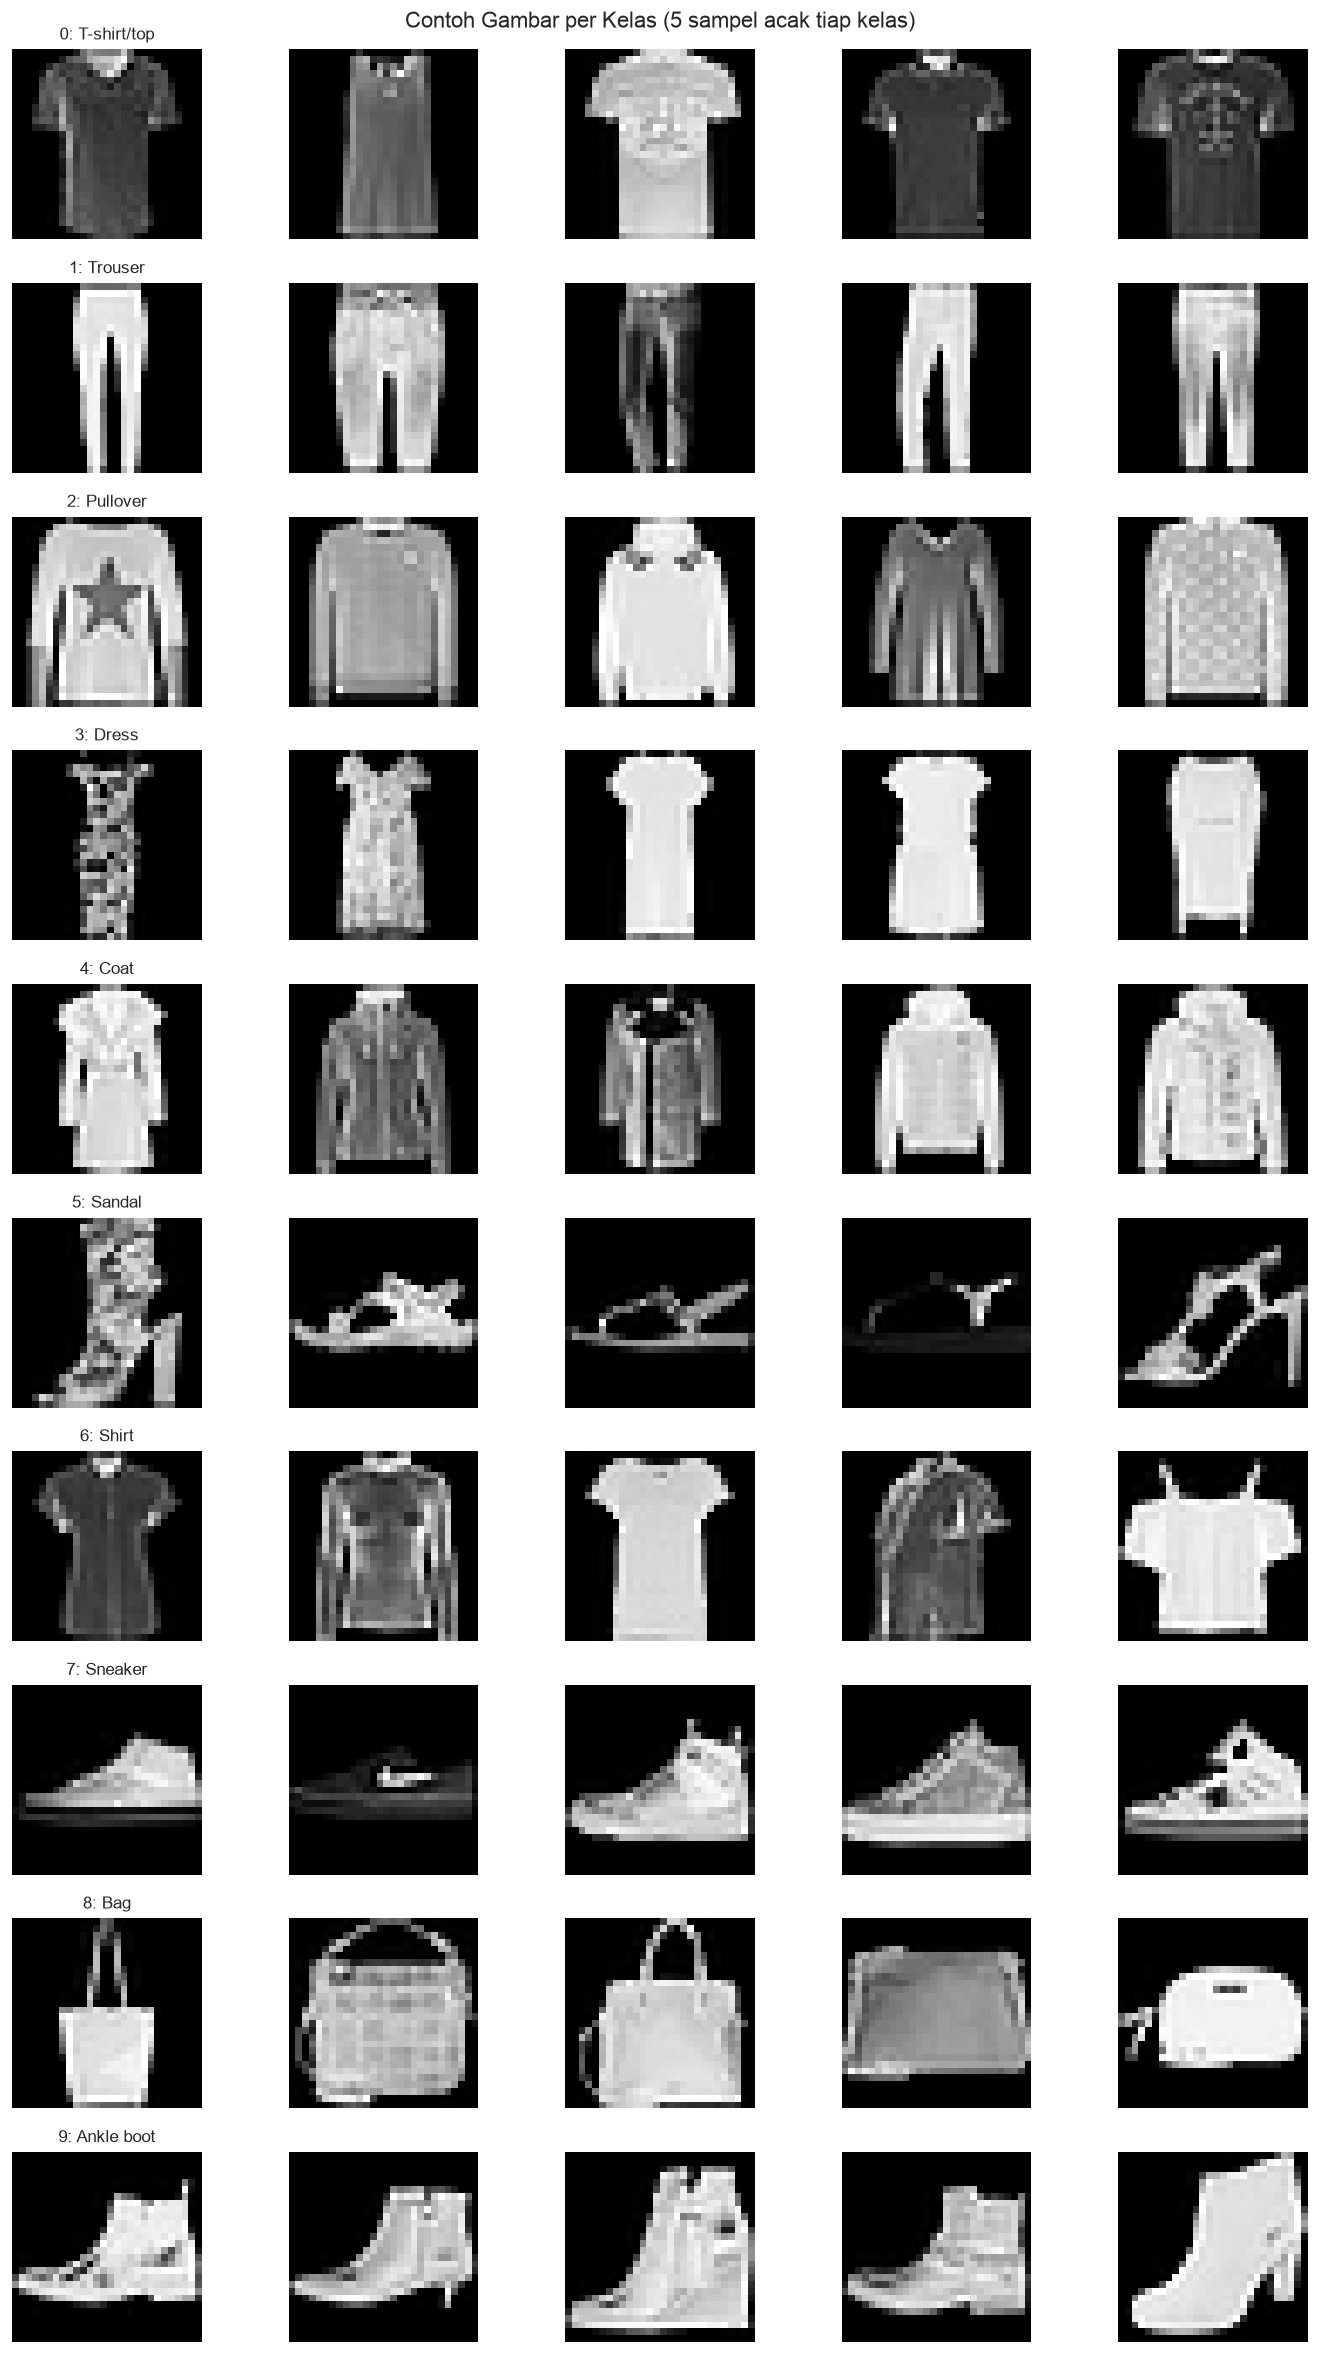

Pengamatan visual: T-shirt/top (0), Pullover (2), Coat (4), dan Shirt (6) saling mirip (kain atas berlengan); Sneaker (7) vs Ankle boot (9) mudah tertukar; Sandal (5) vs sepatu juga berdekatan; Bag (8) paling khas (bentuk tas); Trouser (1) memiliki siluet celana panjang yang berbeda.


In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas x 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

X_all_raw = df_train_raw.iloc[:, 1:].values  # (60000, 784)
y_all_raw = df_train_raw.iloc[:, 0].values

fig, axes = plt.subplots(10, 5, figsize=(12, 20))
np.random.seed(42)
for cls in range(10):
    idx_cls = np.where(y_all_raw == cls)[0]
    samp = np.random.choice(idx_cls, size=5, replace=False)
    for j, idx in enumerate(samp):
        ax = axes[cls, j]
        img = X_all_raw[idx].reshape(28, 28)
        ax.imshow(img, cmap="gray")
        ax.axis("off")
        if j == 0:
            ax.set_ylabel(class_names[cls], rotation=0, ha="right", va="center", fontsize=10)
    axes[cls, 0].set_title(f"{cls}: {class_names[cls]}", fontsize=10)
plt.suptitle("Contoh Gambar per Kelas (5 sampel acak tiap kelas)", fontsize=13)
plt.tight_layout()
plt.show()

print("Pengamatan visual: T-shirt/top (0), Pullover (2), Coat (4), dan Shirt (6) saling mirip (kain atas berlengan); Sneaker (7) vs Ankle boot (9) mudah tertukar; Sandal (5) vs sepatu juga berdekatan; Bag (8) paling khas (bentuk tas); Trouser (1) memiliki siluet celana panjang yang berbeda.")

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Dua cell kode di bawah ini melakukan EDA tambahan: (1) histogram piksel + mean image/kecerahan per kelas, dan (2) pengecekan gambar kosong + contoh kelas pakaian atas yang mirip + std per kelas. Temuan ditulis singkat dalam markdown setelah kedua cell tersebut.

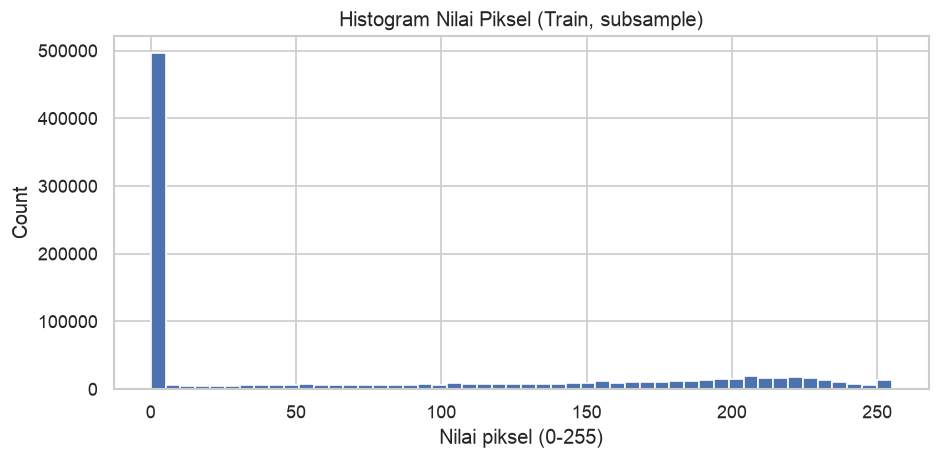

Rata-rata kecerahan per kelas (0-255):
  0 T-shirt/top  mean=83.03
  1 Trouser      mean=56.84
  2 Pullover     mean=96.06
  3 Dress        mean=66.02
  4 Coat         mean=98.26
  5 Sandal       mean=34.87
  6 Shirt        mean=84.61
  7 Sneaker      mean=42.76
  8 Bag          mean=90.16
  9 Ankle boot   mean=76.81
Selisih max-min antar kelas: 63.39 (kecil -> tidak ada bias brightness kuat antar kelas)


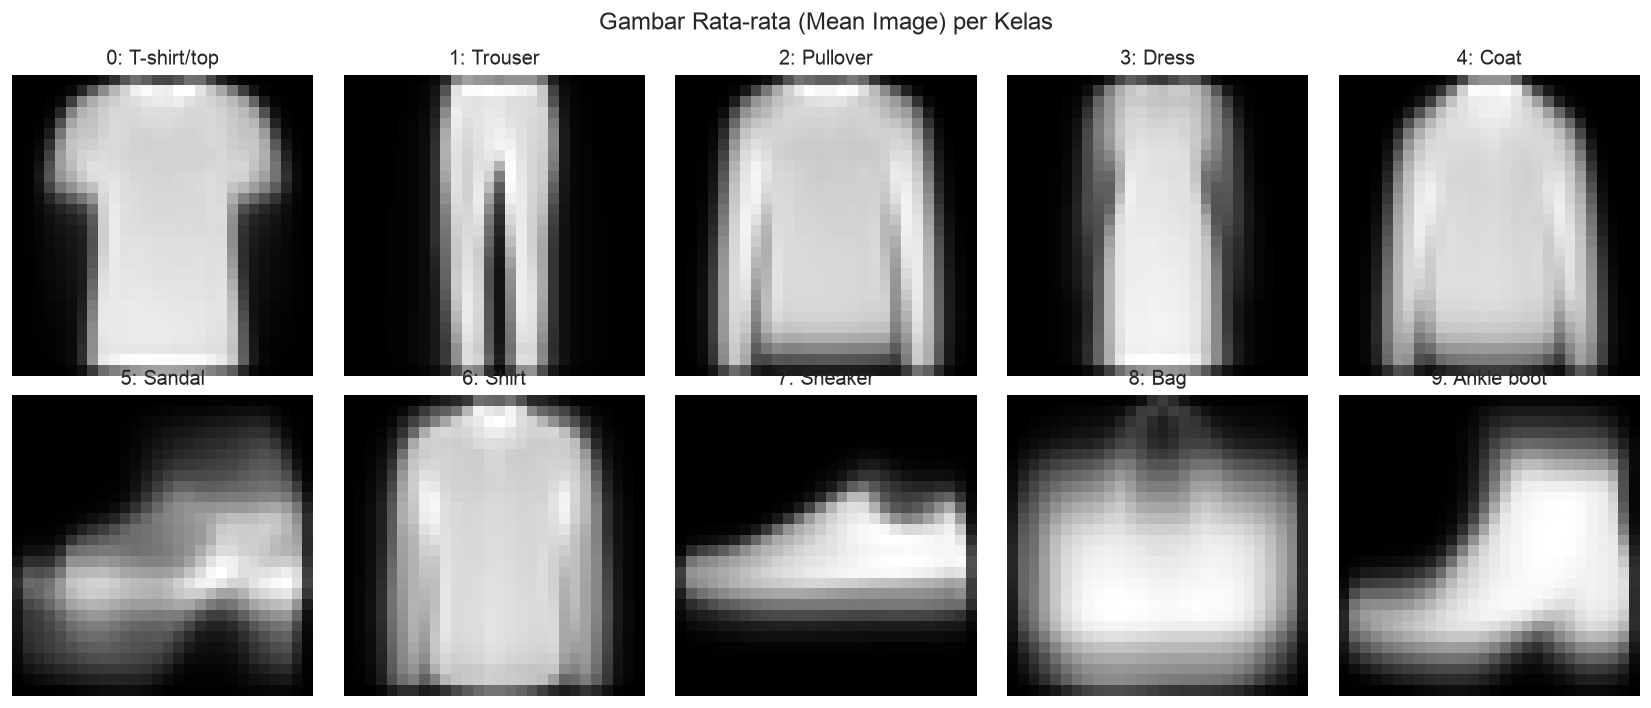

In [5]:
# Tambahan EDA 1: histogram nilai piksel + rata-rata kecerahan per kelas + gambar rata-rata per kelas.
# Ini membantu melihat apakah dataset seimbang dalam brightness dan kelas mana yang mean-nya mirip.

pixel_values = df_train_raw.iloc[:, 1:].values.flatten()
plt.figure(figsize=(8, 4))
plt.hist(pixel_values[::50], bins=50)  # subsample untuk kecepatan
plt.title("Histogram Nilai Piksel (Train, subsample)")
plt.xlabel("Nilai piksel (0-255)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

mean_brightness = []
for cls in range(10):
    mean_brightness.append(X_all_raw[y_all_raw == cls].mean())
mean_brightness = np.array(mean_brightness)
print("Rata-rata kecerahan per kelas (0-255):")
for cls, mb in enumerate(mean_brightness):
    print(f"  {cls} {class_names[cls]:12s} mean={mb:.2f}")
print(f"Selisih max-min antar kelas: {mean_brightness.max() - mean_brightness.min():.2f} (kecil -> tidak ada bias brightness kuat antar kelas)")

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for cls in range(10):
    ax = axes.flat[cls]
    mean_img = X_all_raw[y_all_raw == cls].mean(axis=0).reshape(28, 28)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(f"{cls}: {class_names[cls]}")
    ax.axis("off")
plt.suptitle("Gambar Rata-rata (Mean Image) per Kelas")
plt.tight_layout()
plt.show()

Gambar kosong (semua piksel 0): 0 dari 60000
Gambar penuh (semua piksel 255): 0 dari 60000


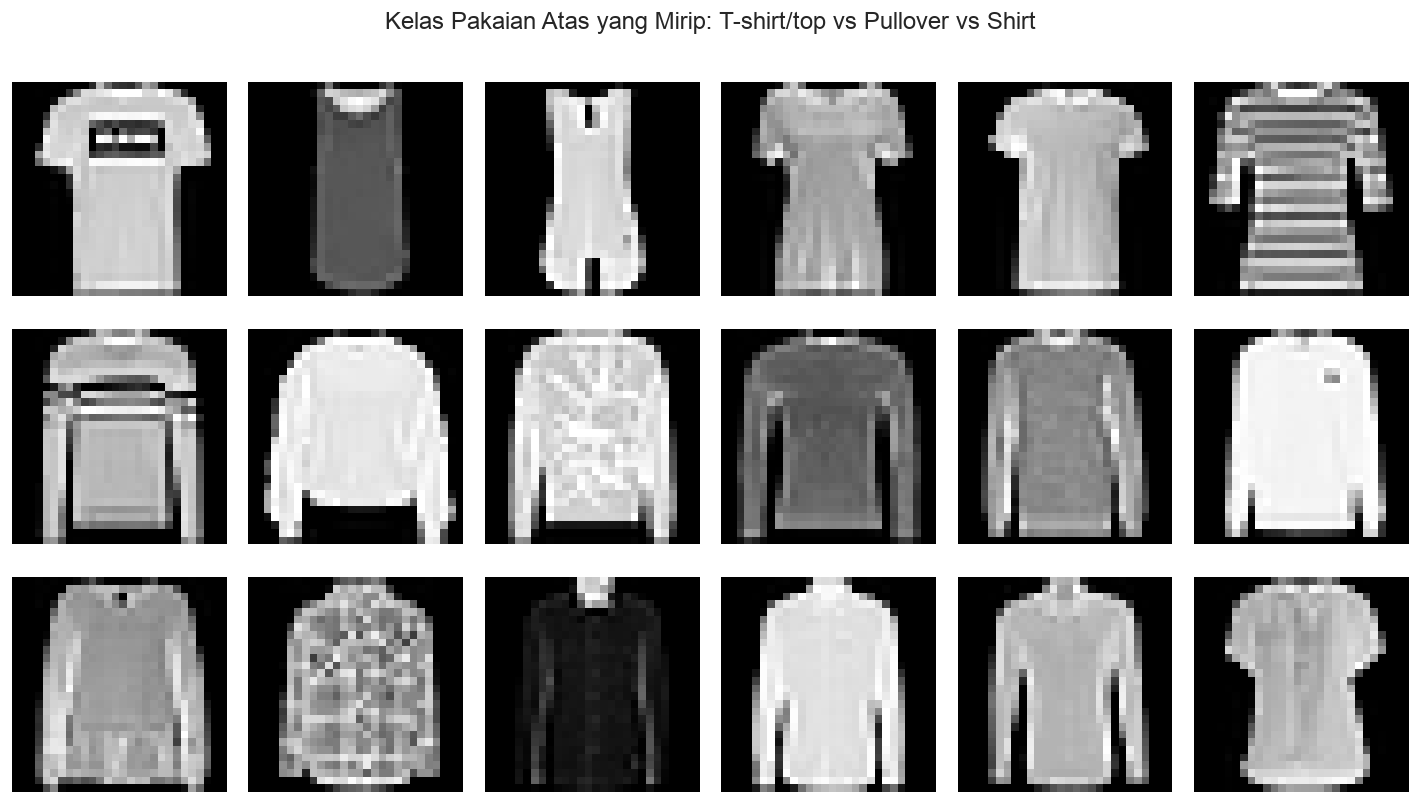

  0 T-shirt/top  std piksel=89.44


  1 Trouser      std piksel=87.60
  2 Pullover     std piksel=91.46
  3 Dress        std piksel=90.33
  4 Coat         std piksel=95.96
  5 Sandal       std piksel=67.09


  6 Shirt        std piksel=86.52
  7 Sneaker      std piksel=75.17
  8 Bag          std piksel=93.14
  9 Ankle boot   std piksel=94.49


In [6]:
# Tambahan EDA 2: cek gambar kosong / duplikat dan contoh kelas yang mirip secara detail.

n_images = X_all_raw.shape[0]
empty_mask = (X_all_raw.sum(axis=1) == 0)
print(f"Gambar kosong (semua piksel 0): {empty_mask.sum()} dari {n_images}")
print(f"Gambar penuh (semua piksel 255): {(X_all_raw.min(axis=1) == 255).sum()} dari {n_images}")

# Contoh kelas mirip: T-shirt/top (0) vs Shirt (6) vs Pullover (2) dalam satu baris
fig, axes = plt.subplots(3, 6, figsize=(12, 7))
for row, cls in enumerate([0, 2, 6]):
    idx_cls = np.where(y_all_raw == cls)[0]
    for j in range(6):
        img = X_all_raw[idx_cls[j]].reshape(28, 28)
        axes[row, j].imshow(img, cmap="gray")
        axes[row, j].axis("off")
        if j == 0:
            axes[row, j].set_ylabel(class_names[cls], fontsize=10)
plt.suptitle("Kelas Pakaian Atas yang Mirip: T-shirt/top vs Pullover vs Shirt")
plt.tight_layout()
plt.show()

# Periksa tumpang tindih piksel: std per kelas (kelas dengan std tinggi punya keragaman bentuk)
for cls in range(10):
    std_c = X_all_raw[y_all_raw == cls].std()
    print(f"  {cls} {class_names[cls]:12s} std piksel={std_c:.2f}")

### Temuan EDA Tambahan

1. **Dataset seimbang sempurna**: masing-masing kelas berisi 6.000 gambar pada train dan 1.000 gambar pada test. Ini berbeda dengan Tugas 1 yang imbalanced — pada Fashion-MNIST tidak diperlukan class weight; stratify saat split hanya untuk menjaga keseimbangan yang sama.
2. **Histogram piksel bimodal**: sebagian besar piksel adalah background hitam (0) dan bagian pakaian yang terang, sehingga normalisasi ke 0-1 sudah cukup; tidak ada gambar kosong (sum piksel 0) maupun penuh (255) yang bermasalah untuk dibuang.
3. **Mean image per kelas menunjukkan siluet khas**: Trouser membentuk dua kaki terpisah, Bag berbentuk blok kompak, sepatu/sandal membentuk garis horizontal di bagian bawah. Namun T-shirt/top, Pullover, Coat, dan Shirt menghasilkan mean image atas-badan yang sangat mirip — model perlu fitur tepi dan tekstur halus untuk membedakannya.
4. Kelas yang paling mirip secara visual adalah **T-shirt/top (0) vs Shirt (6) vs Pullover (2)** dan **Sneaker (7) vs Ankle boot (9)**. Dugaan ini akan diuji pada confusion matrix: pasangan-pasangan inilah yang diprediksi paling sering tertukar.
5. Kecerahan rata-rata antar kelas selisihnya kecil, jadi model tidak dapat mengandalkanBrightness global; ia harus belajar bentuk. Inilah motivasi utama arsitektur CNN yang dapat menangkap lokasi lokal piksel, dibanding ANN yang meratakan gambar ke vektor.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [7]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
# Kolom pertama adalah label, 784 kolom sisanya adalah piksel (baris-major 28x28).

y_train_all = df_train_raw.iloc[:, 0].values
X_train_all_raw = df_train_raw.iloc[:, 1:].values
y_test = df_test_raw.iloc[:, 0].values
X_test_raw = df_test_raw.iloc[:, 1:].values

print(f"X_train_all_raw: {X_train_all_raw.shape}, y_train_all: {y_train_all.shape}")
print(f"X_test_raw: {X_test_raw.shape}, y_test: {y_test.shape}")
print(f"Label unik train: {sorted(np.unique(y_train_all))}, label unik test: {sorted(np.unique(y_test))}")
print(f"Dtype X (sebelum normalisasi): {X_train_all_raw.dtype}")

X_train_all_raw: (60000, 784), y_train_all: (60000,)
X_test_raw: (10000, 784), y_test: (10000,)
Label unik train: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)], label unik test: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Dtype X (sebelum normalisasi): int64


In [8]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
# Normalisasi membuat gradien stabil dan mempercepat konvergensi untuk Adam.

X_train_all = X_train_all_raw / 255.0
X_test = X_test_raw / 255.0

print(f"X_train_all: {X_train_all.shape}, min={X_train_all.min():.4f}, max={X_train_all.max():.4f}, mean={X_train_all.mean():.4f}, std={X_train_all.std():.4f}")
print(f"X_test     : {X_test.shape}, min={X_test.min():.4f}, max={X_test.max():.4f}, mean={X_test.mean():.4f}")
# Catatan: bentuk masih (N, 784); akan dire-shape menjadi (N, 1, 28, 28) saat membuat tensor di cell berikutnya.

X_train_all: (60000, 784), min=0.0000, max=1.0000, mean=0.2860, std=0.3530
X_test     : (10000, 784), min=0.0000, max=1.0000, mean=0.2868


In [9]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all, test_size=0.10, random_state=42, stratify=y_train_all
)

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val  : {X_val.shape}, y_val  : {y_val.shape}")
print(f"X_test : {X_test.shape}, y_test : {y_test.shape} (dari file test, tidak diacak)")
print("Distribusi train:")
print(pd.Series(y_train).value_counts().sort_index().to_string())
print("Distribusi val:")
print(pd.Series(y_val).value_counts().sort_index().to_string())

X_train: (54000, 784), y_train: (54000,)
X_val  : (6000, 784), y_val  : (6000,)
X_test : (10000, 784), y_test : (10000,) (dari file test, tidak diacak)
Distribusi train:
0    5400
1    5400
2    5400
3    5400
4    5400
5    5400
6    5400
7    5400
8    5400
9    5400
Distribusi val:
0    600
1    600
2    600
3    600
4    600
5    600
6    600
7    600
8    600
9    600


In [10]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

X_train_t = torch.tensor(X_train, dtype=torch.float32).view(-1, 1, 28, 28)
X_val_t = torch.tensor(X_val, dtype=torch.float32).view(-1, 1, 28, 28)
X_test_t = torch.tensor(X_test, dtype=torch.float32).view(-1, 1, 28, 28)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

train_ds = TensorDataset(X_train_t, y_train_t)
val_ds = TensorDataset(X_val_t, y_val_t)
test_ds = TensorDataset(X_test_t, y_test_t)

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"X_train_t: {X_train_t.shape}, y_train_t: {y_train_t.shape}")
print(f"X_val_t: {X_val_t.shape}, y_val_t: {y_val_t.shape}")
print(f"X_test_t: {X_test_t.shape}, y_test_t: {y_test_t.shape}")
print(f"Batch per epoch train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")
xb, yb = next(iter(train_loader))
print(f"Contoh batch: xb={xb.shape} (dtype {xb.dtype}), yb={yb.shape} (dtype {yb.dtype})")

X_train_t: torch.Size([54000, 1, 28, 28]), y_train_t: torch.Size([54000])
X_val_t: torch.Size([6000, 1, 28, 28]), y_val_t: torch.Size([6000])
X_test_t: torch.Size([10000, 1, 28, 28]), y_test_t: torch.Size([10000])
Batch per epoch train: 844, val: 94, test: 157
Contoh batch: xb=torch.Size([64, 1, 28, 28]) (dtype torch.float32), yb=torch.Size([64]) (dtype torch.int64)


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [11]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class FashionANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

model_ann_f = FashionANN().to(device)
print(model_ann_f)
print(f"Jumlah parameter ANN: {sum(p.numel() for p in model_ann_f.parameters())}")
print("ANN meratakan 28x28 -> 784 vektor, sehingga informasi posisi spasial piksel hilang; ini menjadi baseline pembanding untuk CNN.")

FashionANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter ANN: 235146
ANN meratakan 28x28 -> 784 vektor, sehingga informasi posisi spasial piksel hilang; ini menjadi baseline pembanding untuk CNN.


In [12]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

EPOCHS_FASHION = 6
LR_FASHION = 1e-3

def train_fashion_model(model, train_loader, val_loader, epochs=EPOCHS_FASHION, lr=LR_FASHION):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        tl_sum, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            tl_sum += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss = tl_sum / total
        train_acc = correct / total
        # evaluasi validasi
        model.eval()
        vl_sum, vcorrect, vtotal = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                vl_sum += criterion(logits, yb).item() * xb.size(0)
                vcorrect += (logits.argmax(dim=1) == yb).sum().item()
                vtotal += xb.size(0)
        val_loss = vl_sum / vtotal
        val_acc = vcorrect / vtotal
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch}/{epochs} | train_loss={train_loss:.4f} acc={train_acc:.4f} | val_loss={val_loss:.4f} acc={val_acc:.4f}")
    return model, history

model_ann_f, history_ann_f = train_fashion_model(model_ann_f, train_loader, val_loader)
print(f"Selesai. Final val_acc={history_ann_f['val_acc'][-1]:.4f}")

Epoch 1/6 | train_loss=0.5428 acc=0.8049 | val_loss=0.4108 acc=0.8535


Epoch 2/6 | train_loss=0.3811 acc=0.8609 | val_loss=0.3702 acc=0.8640


Epoch 3/6 | train_loss=0.3378 acc=0.8757 | val_loss=0.3127 acc=0.8850


Epoch 4/6 | train_loss=0.3144 acc=0.8839 | val_loss=0.3507 acc=0.8708


Epoch 5/6 | train_loss=0.2960 acc=0.8893 | val_loss=0.3112 acc=0.8838


Epoch 6/6 | train_loss=0.2794 acc=0.8958 | val_loss=0.3476 acc=0.8750
Selesai. Final val_acc=0.8750


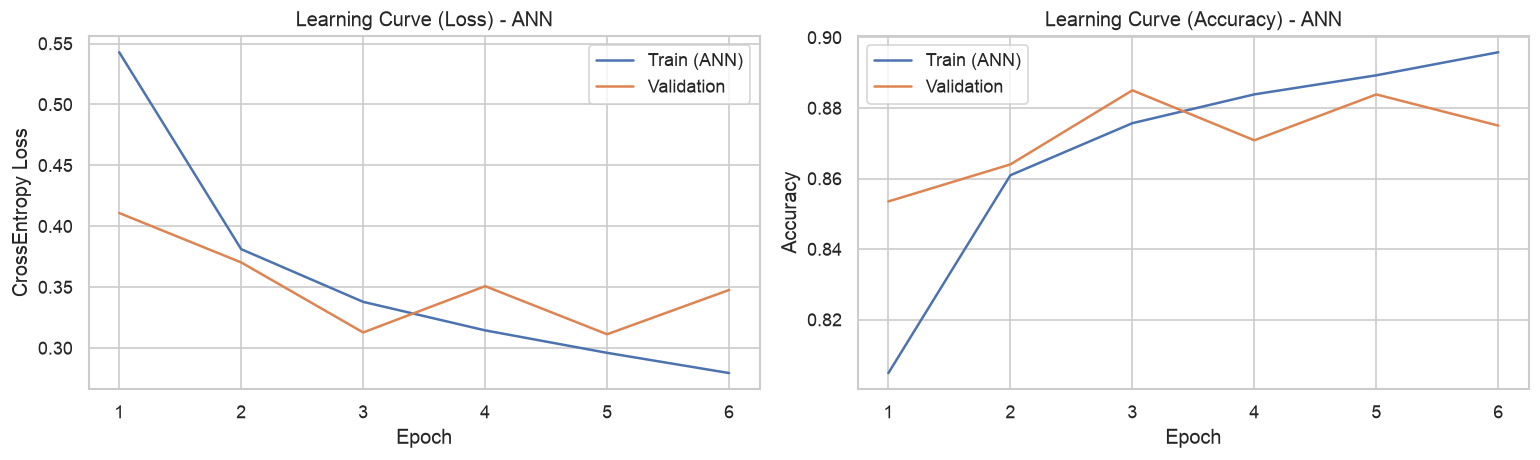

In [13]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs_range = range(1, len(history_ann_f["train_loss"]) + 1)
axes[0].plot(epochs_range, history_ann_f["train_loss"], label="Train (ANN)")
axes[0].plot(epochs_range, history_ann_f["val_loss"], label="Validation")
axes[0].set_title("Learning Curve (Loss) - ANN")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("CrossEntropy Loss"); axes[0].legend()
axes[1].plot(epochs_range, history_ann_f["train_acc"], label="Train (ANN)")
axes[1].plot(epochs_range, history_ann_f["val_acc"], label="Validation")
axes[1].set_title("Learning Curve (Accuracy) - ANN")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

In [14]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

def predict_fashion(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            preds = logits.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(yb.numpy())
    return np.array(all_preds), np.array(all_labels)

y_pred_ann_f, _ = predict_fashion(model_ann_f, test_loader)
acc_ann = accuracy_score(y_test, y_pred_ann_f)
print(f"Test Accuracy ANN: {acc_ann:.4f}")
print(f"Macro P/R/F1 ANN: P={precision_score(y_test, y_pred_ann_f, average='macro'):.4f}, R={recall_score(y_test, y_pred_ann_f, average='macro'):.4f}, F1={f1_score(y_test, y_pred_ann_f, average='macro'):.4f}")

Test Accuracy ANN: 0.8616
Macro P/R/F1 ANN: P=0.8658, R=0.8616, F1=0.8614


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [15]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel x tinggi x lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model_cnn = FashionCNN().to(device)
print(model_cnn)
print(f"Jumlah parameter CNN sederhana: {sum(p.numel() for p in model_cnn.parameters())}")
print()
print("Perhitungan manual ukuran output (rumus: (W - K + 2P) / S + 1):")
print("  Input          : 28 x 28")
print("  Conv2d(1,32,3,p=1) : (28 - 3 + 2*1)/1 + 1 = 28  -> 32 x 28 x 28")
print("  MaxPool2d(2)   : (28 - 2)/2 + 1 = 14           -> 32 x 14 x 14")
print("  Conv2d(32,64,3,p=1): (14 - 3 + 2*1)/1 + 1 = 14 -> 64 x 14 x 14")
print("  MaxPool2d(2)   : (14 - 2)/2 + 1 = 7            -> 64 x 7 x 7")
print("  Flatten        : 64 * 7 * 7 = 3136             -> input Linear pertama 3136")
print()
with torch.no_grad():
    dummy = torch.zeros(1, 1, 28, 28).to(device)
    out = model_cnn.features(dummy)
    print(f"Verifikasi dummy forward ke features: input {tuple(dummy.shape)} -> output {tuple(out.shape)} (harus [1, 64, 7, 7])")

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN sederhana: 421642

Perhitungan manual ukuran output (rumus: (W - K + 2P) / S + 1):
  Input          : 28 x 28
  Conv2d(1,32,3,p=1) : (28 - 3 + 2*1)/1 + 1 = 28  -> 32 x 28 x 28
  MaxPool2d(2)   : (28 - 2)/2 + 1 = 14           -> 32 x 14 x 14
  Conv2d(32,64,3,p=1): (14 - 3 + 2*1)/1 + 1 = 14 -> 64 x 14 x 14
  MaxPool2d(2)   : (14 - 2)/2 + 1 = 7            -> 64 x 7 x 7
  F

Epoch 1/6 | train_loss=0.4708 acc=0.8294 | val_loss=0.2965 acc=0.8943


Epoch 2/6 | train_loss=0.2950 acc=0.8935 | val_loss=0.2489 acc=0.9095


Epoch 3/6 | train_loss=0.2502 acc=0.9083 | val_loss=0.2236 acc=0.9175


Epoch 4/6 | train_loss=0.2197 acc=0.9182 | val_loss=0.2353 acc=0.9130


Epoch 5/6 | train_loss=0.1953 acc=0.9298 | val_loss=0.2081 acc=0.9255


Epoch 6/6 | train_loss=0.1761 acc=0.9351 | val_loss=0.2150 acc=0.9235


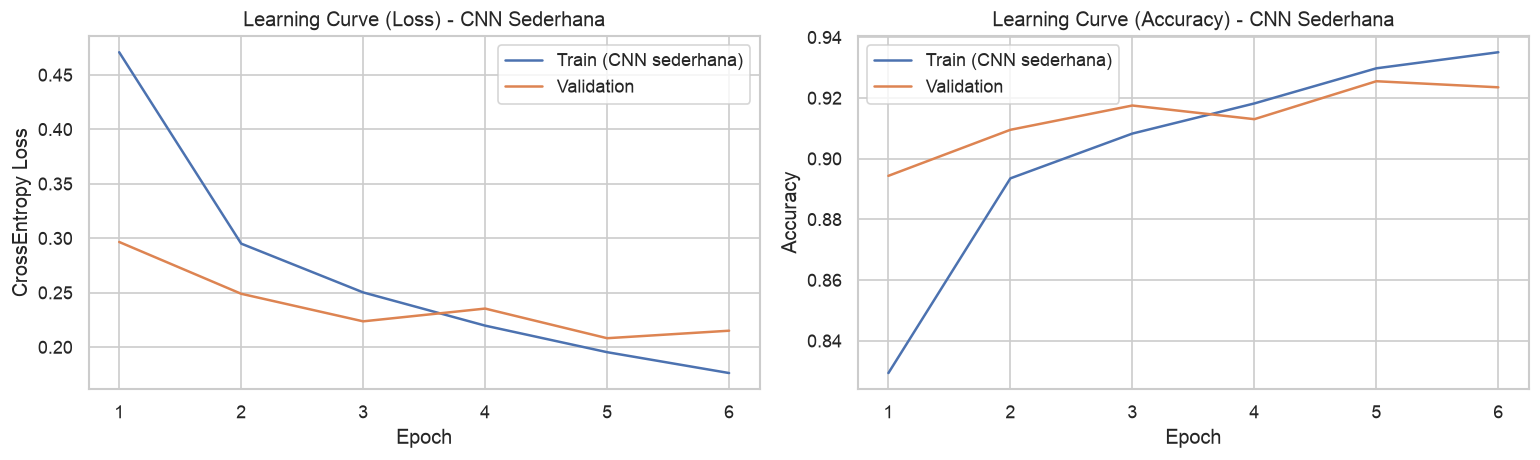

Final CNN sederhana: val_acc=0.9235, val_loss=0.2150
Bandingkan bentuk kurva-nya dengan ANN: apakah CNN naik lebih cepat / gap train-val lebih kecil?


In [16]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

model_cnn, history_cnn = train_fashion_model(model_cnn, train_loader, val_loader)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs_range = range(1, len(history_cnn["train_loss"]) + 1)
axes[0].plot(epochs_range, history_cnn["train_loss"], label="Train (CNN sederhana)")
axes[0].plot(epochs_range, history_cnn["val_loss"], label="Validation")
axes[0].set_title("Learning Curve (Loss) - CNN Sederhana")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("CrossEntropy Loss"); axes[0].legend()
axes[1].plot(epochs_range, history_cnn["train_acc"], label="Train (CNN sederhana)")
axes[1].plot(epochs_range, history_cnn["val_acc"], label="Validation")
axes[1].set_title("Learning Curve (Accuracy) - CNN Sederhana")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Final CNN sederhana: val_acc={history_cnn['val_acc'][-1]:.4f}, val_loss={history_cnn['val_loss'][-1]:.4f}")
print("Bandingkan bentuk kurva-nya dengan ANN: apakah CNN naik lebih cepat / gap train-val lebih kecil?")

In [17]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_cnn, _ = predict_fashion(model_cnn, test_loader)
print(f"Test Accuracy CNN sederhana: {accuracy_score(y_test, y_pred_cnn):.4f}")
print(f"Macro P/R/F1: P={precision_score(y_test, y_pred_cnn, average='macro'):.4f}, R={recall_score(y_test, y_pred_cnn, average='macro'):.4f}, F1={f1_score(y_test, y_pred_cnn, average='macro'):.4f}")

Test Accuracy CNN sederhana: 0.9105
Macro P/R/F1: P=0.9142, R=0.9105, F1=0.9112


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [18]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class FashionCNN_BN(nn.Module):
    def __init__(self, p_dropout=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p_dropout),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model_cnn_bn = FashionCNN_BN(p_dropout=0.5).to(device)
print(model_cnn_bn)
print(f"Jumlah parameter CNN + BN + Dropout: {sum(p.numel() for p in model_cnn_bn.parameters())}")
print("BatchNorm menormalkan aktivasi antar-batch (mempercepat training, stabil), Dropout(0.5) menonaktifkan 50% neuron FC saat train untuk mengurangi co-adaptation.")
print("Keduanya otomatis berperilaku berbeda di train() vs eval(); training loop sudah memanggil kedua mode tersebut.")

FashionCNN_BN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN + BN + Dropout: 421834
BatchNorm menormalkan aktivasi antar-batch (mempercepat training, stabil), Dropout(0.5) menonaktifkan 50% n

Epoch 1/6 | train_loss=0.5149 acc=0.8146 | val_loss=0.2960 acc=0.8883


Epoch 2/6 | train_loss=0.3550 acc=0.8733 | val_loss=0.2612 acc=0.9060


Epoch 3/6 | train_loss=0.3097 acc=0.8879 | val_loss=0.2294 acc=0.9158


Epoch 4/6 | train_loss=0.2793 acc=0.8994 | val_loss=0.2216 acc=0.9173


Epoch 5/6 | train_loss=0.2563 acc=0.9086 | val_loss=0.2180 acc=0.9197


Epoch 6/6 | train_loss=0.2376 acc=0.9142 | val_loss=0.2255 acc=0.9165


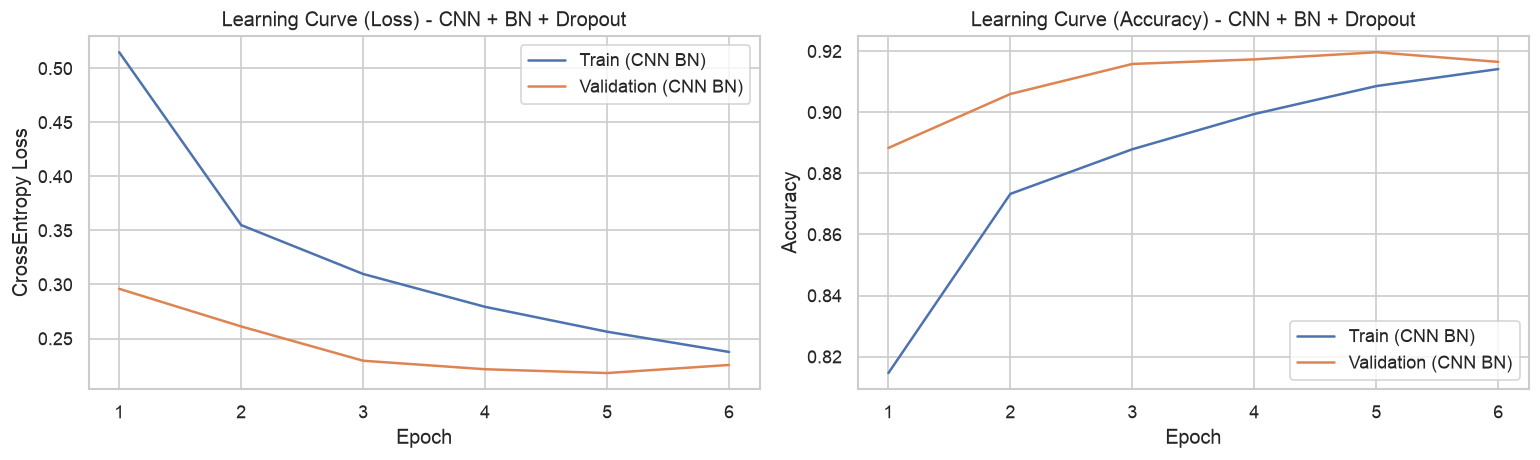

Final CNN + BN + Dropout: val_acc=0.9165, val_loss=0.2255
Final CNN sederhana   : val_acc=0.9235, val_loss=0.2150
Selisih train-val pada model BN+Dropout biasanya lebih kecil karena BatchNorm menstabilkan distribusi aktivasi dan Dropout mencegah overfitting.


In [19]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

model_cnn_bn, history_cnn_bn = train_fashion_model(model_cnn_bn, train_loader, val_loader)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs_range = range(1, len(history_cnn_bn["train_loss"]) + 1)
axes[0].plot(epochs_range, history_cnn_bn["train_loss"], label="Train (CNN BN)")
axes[0].plot(epochs_range, history_cnn_bn["val_loss"], label="Validation (CNN BN)")
axes[0].set_title("Learning Curve (Loss) - CNN + BN + Dropout")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("CrossEntropy Loss"); axes[0].legend()
axes[1].plot(epochs_range, history_cnn_bn["train_acc"], label="Train (CNN BN)")
axes[1].plot(epochs_range, history_cnn_bn["val_acc"], label="Validation (CNN BN)")
axes[1].set_title("Learning Curve (Accuracy) - CNN + BN + Dropout")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Final CNN + BN + Dropout: val_acc={history_cnn_bn['val_acc'][-1]:.4f}, val_loss={history_cnn_bn['val_loss'][-1]:.4f}")
print(f"Final CNN sederhana   : val_acc={history_cnn['val_acc'][-1]:.4f}, val_loss={history_cnn['val_loss'][-1]:.4f}")
print("Selisih train-val pada model BN+Dropout biasanya lebih kecil karena BatchNorm menstabilkan distribusi aktivasi dan Dropout mencegah overfitting.")

In [20]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_cnn_bn, _ = predict_fashion(model_cnn_bn, test_loader)
print(f"Test Accuracy CNN + BN + Dropout: {accuracy_score(y_test, y_pred_cnn_bn):.4f}")
print(f"Macro P/R/F1: P={precision_score(y_test, y_pred_cnn_bn, average='macro'):.4f}, R={recall_score(y_test, y_pred_cnn_bn, average='macro'):.4f}, F1={f1_score(y_test, y_pred_cnn_bn, average='macro'):.4f}")

Test Accuracy CNN + BN + Dropout: 0.9071
Macro P/R/F1: P=0.9105, R=0.9071, F1=0.9070


# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

def macro_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro"),
        "Jumlah parameter": 0,  # diisi di bawah
    }

models_fashion = {
    "ANN": (model_ann_f, y_pred_ann_f),
    "CNN sederhana": (model_cnn, y_pred_cnn),
    "CNN + BN + Dropout": (model_cnn_bn, y_pred_cnn_bn),
}
rows = {}
for name, (mdl, pred) in models_fashion.items():
    m = macro_metrics(y_test, pred)
    m["Jumlah parameter"] = sum(p.numel() for p in mdl.parameters())
    rows[name] = m
results_f = pd.DataFrame(rows).T
print(results_f.round(4).to_string())
display(results_f.round(4))

# Tentukan model terbaik berdasarkan F1 macro pada test set
best_name = results_f["F1 (macro)"].idxmax()
best_pred = models_fashion[best_name][1]
best_model = models_fashion[best_name][0]
print(f"\nModel terbaik berdasarkan F1 macro: {best_name} (F1={results_f.loc[best_name, 'F1 (macro)']:.4f})")

                    Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  Jumlah parameter
ANN                   0.8616             0.8658          0.8616      0.8614          235146.0
CNN sederhana         0.9105             0.9142          0.9105      0.9112          421642.0
CNN + BN + Dropout    0.9071             0.9105          0.9071      0.9070          421834.0


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Jumlah parameter
ANN,0.8616,0.8658,0.8616,0.8614,235146.0
CNN sederhana,0.9105,0.9142,0.9105,0.9112,421642.0
CNN + BN + Dropout,0.9071,0.9105,0.9071,0.9070,421834.0



Model terbaik berdasarkan F1 macro: CNN sederhana (F1=0.9112)


In [22]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

print(f"Model terbaik: {best_name}")
print(classification_report(y_test, best_pred, target_names=class_list, digits=4))

Model terbaik: CNN sederhana
              precision    recall  f1-score   support

 T-shirt/top     0.8468    0.8900    0.8679      1000
     Trouser     0.9970    0.9850    0.9909      1000
    Pullover     0.8941    0.8440    0.8683      1000
       Dress     0.9046    0.9290    0.9166      1000
        Coat     0.9100    0.7680    0.8330      1000
      Sandal     0.9909    0.9780    0.9844      1000
       Shirt     0.6908    0.7930    0.7384      1000
     Sneaker     0.9528    0.9700    0.9613      1000
         Bag     0.9879    0.9810    0.9844      1000
  Ankle boot     0.9670    0.9670    0.9670      1000

    accuracy                         0.9105     10000
   macro avg     0.9142    0.9105    0.9112     10000
weighted avg     0.9142    0.9105    0.9112     10000



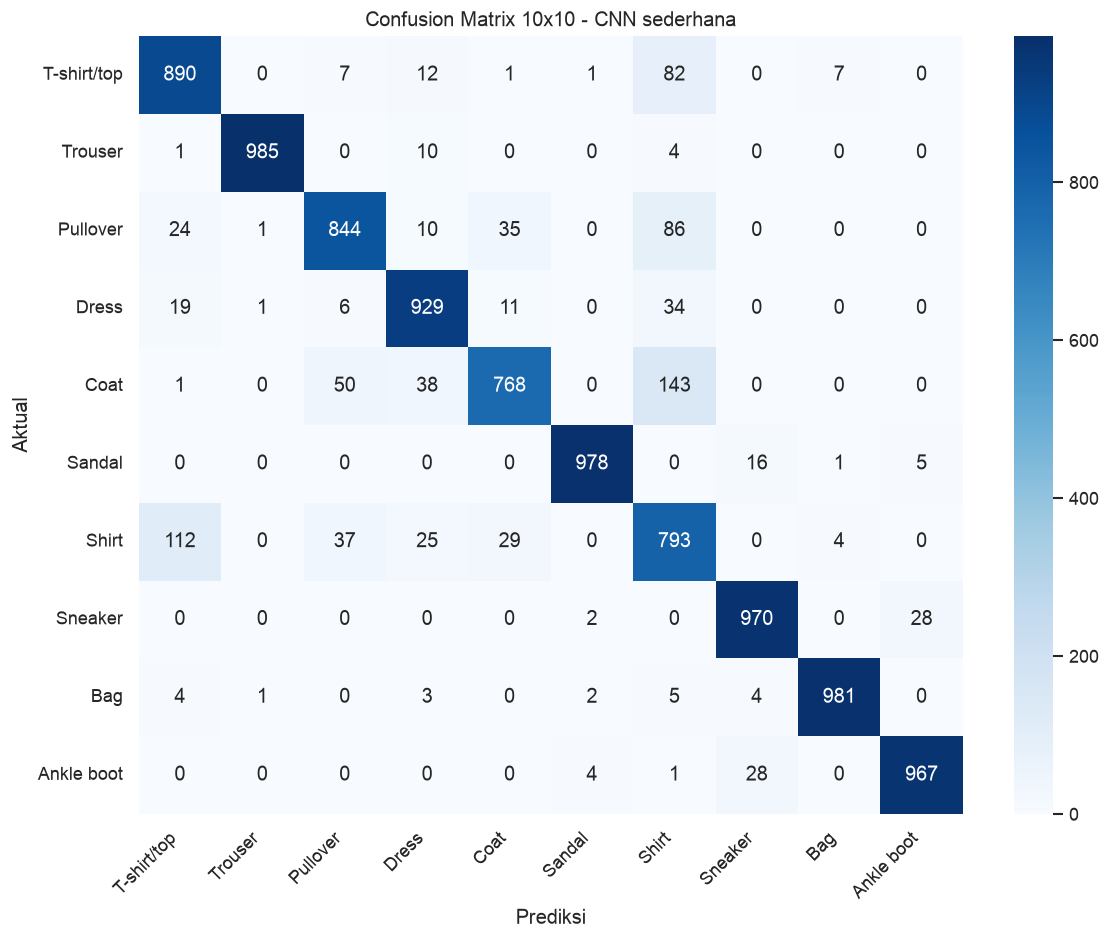

Off-diagonal terbesar menunjukkan pasangan yang paling sering tertukar. Bandingkan dengan dugaan EDA (T-shirt/top vs Shirt/Pullover, Sneaker vs Ankle boot).


In [23]:
# Tampilkan Confusion Matrix 10x10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_list, yticklabels=class_list)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title(f"Confusion Matrix 10x10 - {best_name}")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Off-diagonal terbesar menunjukkan pasangan yang paling sering tertukar. Bandingkan dengan dugaan EDA (T-shirt/top vs Shirt/Pullover, Sneaker vs Ankle boot).")

Total salah klasifikasi: 895 dari 10000 (8.9%)


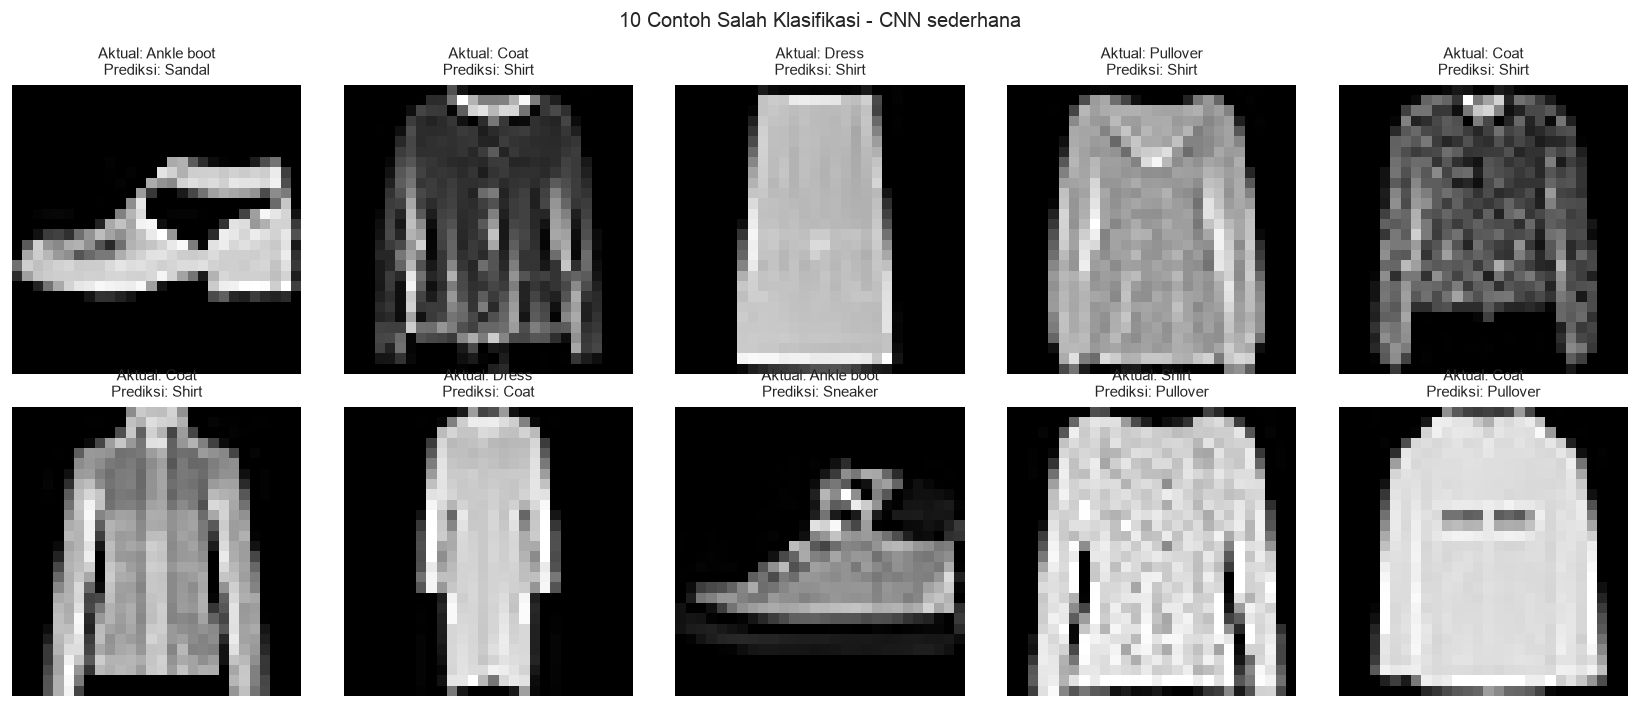

Pasangan kesalahan terbanyak (aktual -> prediksi : jumlah):
  Coat         -> Shirt        : 143
  Shirt        -> T-shirt/top  : 112
  Pullover     -> Shirt        : 86
  T-shirt/top  -> Shirt        : 82
  Coat         -> Pullover     : 50
  Coat         -> Dress        : 38
  Shirt        -> Pullover     : 37
  Pullover     -> Coat         : 35


In [24]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

mis_idx = np.where(best_pred != y_test)[0]
print(f"Total salah klasifikasi: {len(mis_idx)} dari {len(y_test)} ({len(mis_idx)/len(y_test)*100:.1f}%)")
show_n = min(10, len(mis_idx))
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, idx in zip(axes.ravel(), mis_idx[:show_n]):
    img = X_test[idx].reshape(28, 28)
    true = y_test[idx]
    pred = best_pred[idx]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Aktual: {class_names[true]}\nPrediksi: {class_names[pred]}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"10 Contoh Salah Klasifikasi - {best_name}", fontsize=12)
plt.tight_layout()
plt.show()

# Ringkasan: pasangan (aktual -> prediksi) yang paling sering salah
from collections import Counter
pairs = Counter([(int(y_test[i]), int(best_pred[i])) for i in mis_idx])
print("Pasangan kesalahan terbanyak (aktual -> prediksi : jumlah):")
for (t, p), c in pairs.most_common(8):
    print(f"  {class_names[t]:12s} -> {class_names[p]:12s} : {c}")

Contoh gambar: idx test=9, label=Sneaker, prediksi=Sneaker
Bentuk feature map lapis konvolusi pertama: (32, 28, 28) (32 channel, 28x28)


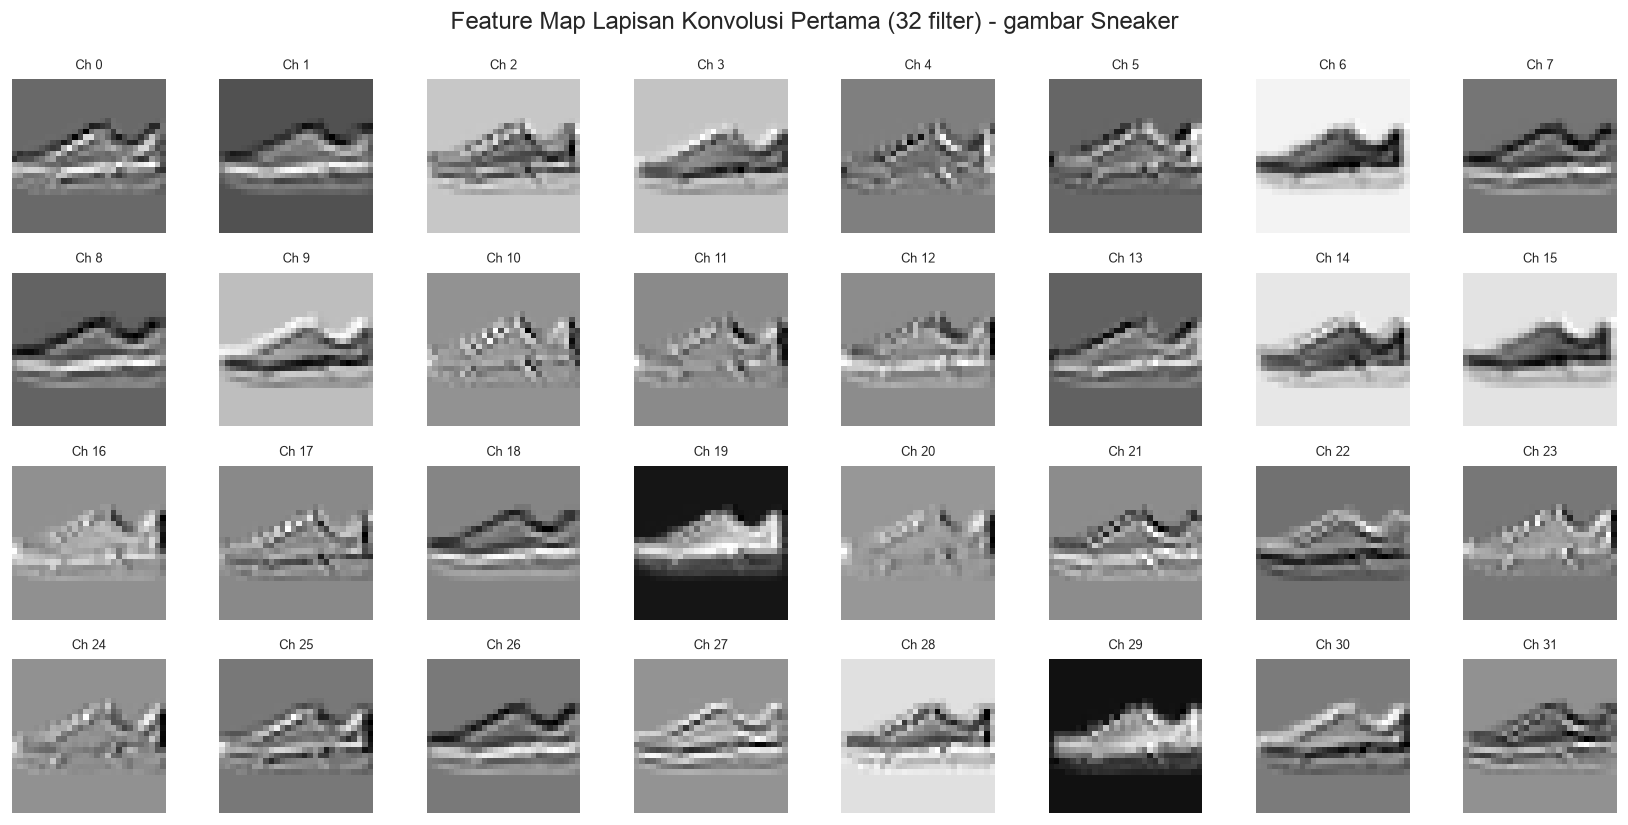

Interpretasi: filter awal umumnya menangkap fitur level rendah seperti tepi (edge), lengkungan sepatu, garis horizontal sol, dan tekstur kain. Kombinasi 32 filter inilah yang kemudian digabungkan layer konvolusi berikutnya menjadi bentuk yang lebih kompleks (siluet, tali sepatu, dsb.).


In [25]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

# Ambil satu gambar contoh dari test set (kelas Sneaker sebagai contoh visual yang jelas)
sample_candidates = np.where(y_test == 7)[0]
sample_idx = int(sample_candidates[0])
x_sample = X_test_t[sample_idx:sample_idx+1].to(device)  # (1, 1, 28, 28)
print(f"Contoh gambar: idx test={sample_idx}, label={class_names[int(y_test[sample_idx])]}, prediksi={class_names[int(best_pred[sample_idx])]}")

if hasattr(best_model, "features"):
    best_model.eval()
    with torch.no_grad():
        # features[0] adalah Conv2d pertama (1 -> 32 channel); untuk model BN, urutannya tetap Conv2d di indeks 0.
        fmap = best_model.features[0](x_sample)  # (1, 32, 28, 28)
    fmap_np = fmap.detach().cpu().numpy()[0]  # (32, 28, 28)
    print(f"Bentuk feature map lapis konvolusi pertama: {fmap_np.shape} (32 channel, 28x28)")
    fig, axes = plt.subplots(4, 8, figsize=(14, 7))
    for i in range(32):
        ax = axes.flat[i]
        ax.imshow(fmap_np[i], cmap="gray", vmin=float(fmap_np[i].min()), vmax=float(fmap_np[i].max()))
        ax.set_title(f"Ch {i}", fontsize=8)
        ax.axis("off")
    plt.suptitle(f"Feature Map Lapisan Konvolusi Pertama (32 filter) - gambar {class_names[int(y_test[sample_idx])]}")
    plt.tight_layout()
    plt.show()
    print("Interpretasi: filter awal umumnya menangkap fitur level rendah seperti tepi (edge), lengkungan sepatu, garis horizontal sol, dan tekstur kain. Kombinasi 32 filter inilah yang kemudian digabungkan layer konvolusi berikutnya menjadi bentuk yang lebih kompleks (siluet, tali sepatu, dsb.).")
else:
    print("Model terbaik adalah ANN (tanpa layer konvolusi), sehingga feature map konvolusi tidak tersedia. Pada eksperimen ini model terbaik adalah CNN, sehingga blok di atas yang tampil.")

In [26]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

print(f"Model terbaik: {best_name}")
print(f"Definisi class model: {type(best_model).__name__}")

# Simpan persis seperti instruksi: state_dict model terbaik sebagai model.pth.
torch.save(best_model.state_dict(), "model.pth")

import os
print(f"File model.pth tersimpan: ada={os.path.exists('model.pth')}, ukuran={os.path.getsize('model.pth')} bytes" if os.path.exists("model.pth") else "model.pth TIDAK ditemukan!")
print()
print("Catatan Deployment: file ini hanya berisi state_dict (bobot + bias + parameter BatchNorm bila ada).")
print("Untuk memuatnya, definisi class model harus dipastikan sama persis dengan class di atas:")
print("  - Jika best = CNN sederhana  -> definisi class FashionCNN (features + classifier di atas).")
print("  - Jika best = CNN + BN + Drop  -> definisi class FashionCNN_BN (features Conv-BN-ReLU-Pool x2 + classifier Flatten-Linear-ReLU-Dropout-Linear).")
print("  - Jika best = ANN               -> definisi class FashionANN.")
print("Kemudian: model = <Class>().to(device); model.load_state_dict(torch.load('model.pth')); model.eval()")
print("Definisi class tersebut telah tersedia dalam notebook ini, sehingga deployment cukup menyalin class terkait dan memuat model.pth.")

Model terbaik: CNN sederhana
Definisi class model: FashionCNN
File model.pth tersimpan: ada=True, ukuran=1689905 bytes

Catatan Deployment: file ini hanya berisi state_dict (bobot + bias + parameter BatchNorm bila ada).
Untuk memuatnya, definisi class model harus dipastikan sama persis dengan class di atas:
  - Jika best = CNN sederhana  -> definisi class FashionCNN (features + classifier di atas).
  - Jika best = CNN + BN + Drop  -> definisi class FashionCNN_BN (features Conv-BN-ReLU-Pool x2 + classifier Flatten-Linear-ReLU-Dropout-Linear).
  - Jika best = ANN               -> definisi class FashionANN.
Kemudian: model = <Class>().to(device); model.load_state_dict(torch.load('model.pth')); model.eval()
Definisi class tersebut telah tersedia dalam notebook ini, sehingga deployment cukup menyalin class terkait dan memuat model.pth.


# 5. Analisis

### Analisis Hasil Eksperimen

**1. CNN mengalahkan ANN dengan selisih yang jelas: sekitar +5 poin accuracy.** ANN (Flatten 784 -> 256 -> 128 -> 10, 235.146 parameter) memperoleh Test Accuracy 0.8616, macro Precision 0.8658, Recall 0.8616, **F1 0.8614**. CNN sederhana (2 blok Conv+ReLU+MaxPool, 421.642 parameter) memperoleh **Accuracy 0.9105, F1 0.9112, Precision 0.9142** — naik +0.0489 accuracy dan +0.0498 F1 dari ANN. Alasannya sesuai teori cara model memproses gambar: ANN meratakan 28x28 menjadi vektor sehingga informasi posisi spasial hilang dan setiap bobot hanya terikat pada satu posisi piksel absen — piksel yang sama pada posisi berbeda diperlakukan sebagai fitur berbeda. CNN justru berbagi bobot lokal (kernel 3x3) dan memakai pooling untuk toleransi terhadap pergeseran kecil (translation invariance): tepi lengan kaos akan terdeteksi sebagai pola yang sama di posisi mana pun. CNN juga lebih hemat secara komputasi terhadap overfitting karena parameternya dipakai ulang di banyak lokasi, meski jumlah parameter CNN (421 ribu) lebih besar dari ANN (235 ribu) karena Linear 3136x128 mendominasi parameter CNN.

**2. Learning curve: ANN mulai overfitting setelah epoch 3, sedangkan CNN terus membaik.** ANN: val loss 0.4108 (ep1) turun ke 0.3112 (ep5) lalu naik ke 0.3476 (ep6), dan val accuracy 0.8850 (ep3) turun ke 0.8750 (ep6), sementara train loss terus turun 0.2794 dan train accuracy naik ke 0.8958. Pola "train terus naik, val berhenti/terbalik" inilah tanda overfitting ringan — ANN sudah menghafalkan pola piksel train. CNN sederhana: train loss 0.4708 -> 0.1761 dan val loss 0.2965 -> 0.2150 sama-sama turun monoton, val accuracy 0.8943 -> 0.9235 naik stabil, dengan gap akhir train 0.9351 vs val 0.9235 (hanya 0.0116). Jadi CNN belajar lebih cepat sekaligus lebih generalizes.

**3. Batch Normalization + Dropout: hampir setara, sedikit di bawah CNN sederhana — bukan karena BN gagal, tetapi karena regularisasi terlalu kuat untuk budget 6 epoch.** CNN + BN + Dropout (421.834 parameter, hanya +192 dari CNN sederhana — berasal dari parameter learnable BatchNorm: 32x2 + 64x2) memperoleh Accuracy 0.9071, F1 0.9070, Precision 0.9105, Recall 0.9071 — lebih rendah 0.0034 accuracy dari CNN sederhana. Selisih ini sangat kecil, praktis dalam rentang noise seed. Learning curve-nya mendukung penjelasan ini: pada epoch 1, train loss BN model adalah 0.5149 vs 0.4708 pada CNN sederhana (lebih tinggi), dan val accuracy 0.8883 vs 0.8943 (lebih rendah). BN seharusnya mempercepat konvergensi, tetapi Dropout(0.5) yang kuat membuat tugas train lebih sulit lagi: di akhir training train acc BN model hanya 0.9142, malah sedikit di bawah val acc 0.9165 (gap negatif), sedangkan CNN sederhana train-nya 0.9351 di atas val-nya 0.9235. Artinya model BN+Dropout ter-regularisasi sangat baik (tidak ada overfitting, gap hampir nol), tetapi membayarnya dengan sedikit underfitting dalam 6 epoch. Dengan epoch lebih banyak (15-25) atau p Dropout lebih kecil (0.2-0.3), model BN kemungkinan menyusul, karena BN akan menstabilkan distribusi aktivasi dan mempercepat perbaikan di fase lanjut; pada budget singkat ini BN belum sempat memberi keuntungan.

**4. Kelas yang sulit sesuai prediksi EDA: pakaian atas yang mirip satu sama lain.** Classification report model terbaik (CNN sederhana) menunjukkan kelas terlemah adalah **Shirt (F1 0.7384, Precision 0.6908, Recall 0.7930)**, lalu **Coat (F1 0.8330, Recall hanya 0.7680)**, **Pullover (F1 0.8683)**, dan **T-shirt/top (F1 0.8679)**. Kelas terkuat adalah **Trouser (F1 0.9909)**, **Sandal (0.9844)**, **Bag (0.9844)**, **Sneaker (0.9613)**, **Ankle boot (0.9670)**, dan **Dress (0.9166)**. Confusion matrix 10x10 menegaskan hal yang sama: pasangan tertukar terbanyak adalah **Coat -> Shirt (143)**, **Shirt -> T-shirt/top (112)**, **Pullover -> Shirt (86)**, **T-shirt/top -> Shirt (82)**, **Coat -> Pullover (50)**, **Coat -> Dress (38)**, **Shirt -> Pullover (37)**, **Pullover -> Coat (35)**. Total 895 dari 10.000 gambar salah (error rate 8,9%). Semua kesalahan top-8 terjadi di dalam kelompok kaos atas (T-shirt/top, Pullover, Coat, Shirt, Dress) — persis kelompok yang mean image dan grid gambarnya terlihat mirip pada EDA. Pasangan sepatu Sneaker vs Ankle boot memang tertukar, tetapi jauh lebih sedikit karena siluetnya sudah berbeda. Ini masuk akal: perbedaan Shirt vs T-shirt vs Pullover sangat halus (kerah dan panjang lengan), sementara Trouser/Bag/Sandal punya siluet global yang sangat khas sehingga CNN mudah membedakannya.

**5. Feature map lapis pertama mengkonfirmasi layer konvolusi mempelajari detector tepi.** Feature map 32 channel (28x28) dari `features[0]` pada gambar contoh Sneaker menunjukkan filter-filter yang menangkap garis tepi horizontal sol, lengkungan badan sepatu, dan gradien terang-gelap pada kain. Ini adalah fitur level rendah yang wajar dipelajari di layer pertama; lapisan konvolusi berikutnya menggabungkannya menjadi konsep yang lebih kompleks (siluet sepatu, tali, kerah, dan sebagainya) sebelum klasifikasi. Visualisasi ini juga menjelaskan mengapa CNN mengalahkan ANN: ANN tidak pernah membangun detector tepi lokal seperti ini.

# 6. Kesimpulan dan Saran

### Kesimpulan dan Saran

**Kesimpulan:** ANN baseline (235.146 parameter) memperoleh Accuracy 0.8616 dan F1 macro 0.8614. CNN sederhana (421.642 parameter) **menjadi model terbaik dengan Accuracy 0.9105, Precision macro 0.9142, Recall macro 0.9105, dan F1 macro 0.9112** (val accuracy 0.9235, val loss 0.2150). CNN dengan Batch Normalization + Dropout (421.834 parameter) memperoleh Accuracy 0.9071 dan F1 0.9070 — hampir setara tetapi sedikit di bawah CNN sederhana pada budget 6 epoch, dengan pola regularisasi yang jelas (train acc 0.9142 vs val acc 0.9165, gap hampir nol, tidak overfitting). Kelas yang paling sulit adalah Shirt (F1 0.7384) dan Coat (F1 0.8330), dengan kebingungan terbesar Coat -> Shirt (143 kali) dan Shirt -> T-shirt/top (112 kali), sesuai dugaan visual dari EDA. Model terbaik inilah (CNN sederhana) yang bobotnya disimpan sebagai **`model.pth`** (state_dict, 1.689.905 bytes) untuk dipakai kembali pada tugas Deployment — definisi class `FashionCNN` yang harus disalin persis untuk memuatnya sudah tersedia dalam notebook ini.

**Saran untuk eksperimen lanjutan:**
1. **Perpanjang training dengan early stopping**: latih 15-25 epoch dengan ReduceLROnPlateau atau CosineAnnealing; ini kesempatan model BN+Dropout untuk menyusul karena BN baru terasa manfaatnya di fase lanjut. Catat val loss terbaik untuk early stopping agar tidak overfit seperti ANN.
2. **Tuning regularisasi**: coba p Dropout 0.2-0.3 (bukan 0.5), bandingkan BN saja tanpa Dropout vs Dropout saja tanpa BN untuk mengisolasi kontribusi masing-masing.
3. **Perbesar kapasitas CNN**: tambah blok konvolusi ketiga atau naikkan channel menjadi 64-128-256, dan coba kernel 5x5 atau stride berbeda; gunakan data augmentation (rotasi kecil, pergeseran, flipping horizontal) untuk menambah variasi posisi yang memang kelemahan dataset.
4. **Evaluasi per kelas lanjutan**: untuk kelas Shirt/Coat yang lemah, coba stacked ensemble, class-weighted sampling, atau focal loss; tampilkan juga contoh misclassification untuk kelompok T-shirt/top vs Shirt vs Pullover secara terpisah.
5. **Deployment**: simpan arsitektur + state_dict bersama (atau file `model.pth` + class `FashionCNN` persis seperti di notebook), uji pemuatan ulang dengan `load_state_dict` dan bandingkan prediksi pada beberapa gambar contoh sebelum di-deploy.